# Factor Return PCA

Run principal component analysis on monthly factor returns to see how many independent sources of variation the registered factors really contain, and which factors load on which component.

1. Choose the number of components with parallel analysis.
2. Fit the PCA and inspect the loadings.
3. See how factors and source themes (`value`, `quality`, `momentum`, ...) group within components.

Build the inputs first with `python scripts/build_crsp_universe.py` and `python scripts/load_data.py`. Factor calculations are cached under `data/factors`, so only the first run is slow.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from modules.factors.mappings import FACTOR_MAPPINGS
from modules.redundancy.heatmap import _factor_theme, select_factor_returns
from modules.redundancy.pca import parallel_analysis, view_principal_components
from notebooks.utils import (
    calculate_factor_return_data,
    load_aligned_factor_data,
)

## Load factor returns

In [2]:
START_YEAR, END_YEAR = 2004, 2024  # CRSP data ends 2024-12-31

aligned_data = load_aligned_factor_data(start_year=START_YEAR, end_year=END_YEAR)
daily_returns = calculate_factor_return_data(data=aligned_data, start_year=START_YEAR)
del aligned_data  # large panel no longer needed
daily_returns.shape

(5284, 40)

## Monthly returns

`pca.py` is built for monthly factor returns, so compound the daily long-short returns within each calendar month. Months where a factor has no valid daily return stay missing, and PCA needs a complete panel, so only months in which every factor has a return are kept.

In [3]:
factors = select_factor_returns(daily_returns.set_index('date'))
all_months = np.expm1(np.log1p(factors).resample('ME').sum(min_count=1))
monthly_returns = all_months.dropna(how='any')
print(
    f'{len(monthly_returns)} months '
    f'({monthly_returns.index.min():%Y-%m} to {monthly_returns.index.max():%Y-%m}); '
    f'{monthly_returns.shape[1]} factors; '
    f'{len(all_months) - len(monthly_returns)} months dropped for missing factor returns'
)

251 months (2004-01 to 2024-12); 39 factors; 1 months dropped for missing factor returns


## Number of components

Parallel analysis keeps a component only if its eigenvalue beats the 95th percentile of the matching eigenvalue from 1,000 permuted copies of the data, in which factor returns are independent. The scree plot shows the real eigenvalues against the usual Kaiser cutoff of 1.

Parallel analysis retains 6 components (Kaiser criterion: 8)


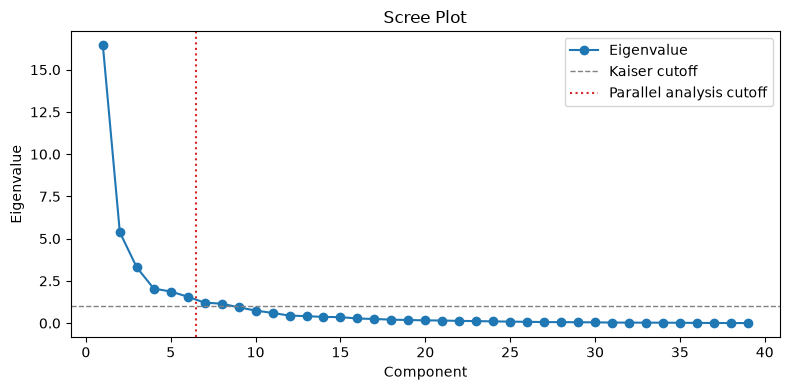

In [4]:
scaled = StandardScaler().fit_transform(monthly_returns)
n_components = parallel_analysis(scaled, n_iter=1000, percentile=95)

eigenvalues = np.linalg.eigvalsh(np.corrcoef(scaled.T))[::-1]
explained = eigenvalues / eigenvalues.sum()
kaiser = int((eigenvalues > 1).sum())
print(f'Parallel analysis retains {n_components} components (Kaiser criterion: {kaiser})')

fig, ax = plt.subplots(figsize=(8, 4))
ranks = np.arange(1, len(eigenvalues) + 1)
ax.plot(ranks, eigenvalues, marker='o', label='Eigenvalue')
ax.axhline(1, color='grey', linestyle='--', linewidth=1, label='Kaiser cutoff')
ax.axvline(n_components + 0.5, color='tab:red', linestyle=':', label='Parallel analysis cutoff')
ax.set_xlabel('Component')
ax.set_ylabel('Eigenvalue')
ax.set_title('Scree Plot')
ax.legend()
plt.tight_layout()
plt.show()

In [5]:
pd.DataFrame(
    {
        'eigenvalue': eigenvalues[:n_components],
        'variance_explained': explained[:n_components],
        'cumulative': explained[:n_components].cumsum(),
    },
    index=[f'PC{i + 1}' for i in range(n_components)],
).round({'eigenvalue': 2, 'variance_explained': 3, 'cumulative': 3})

,eigenvalue,variance_explained,cumulative
PC1,16.45,0.422,0.422
PC2,5.38,0.138,0.560
PC3,3.29,0.084,0.644
PC4,2.05,0.052,0.697
PC5,1.87,0.048,0.745
PC6,1.57,0.040,0.785


## Loadings

Loadings are the weights of each standardized factor in each component. The sign of a component is arbitrary, so what matters is which factors move together (same sign) or against each other (opposite signs). Rows are ordered by absolute PC1 loading.

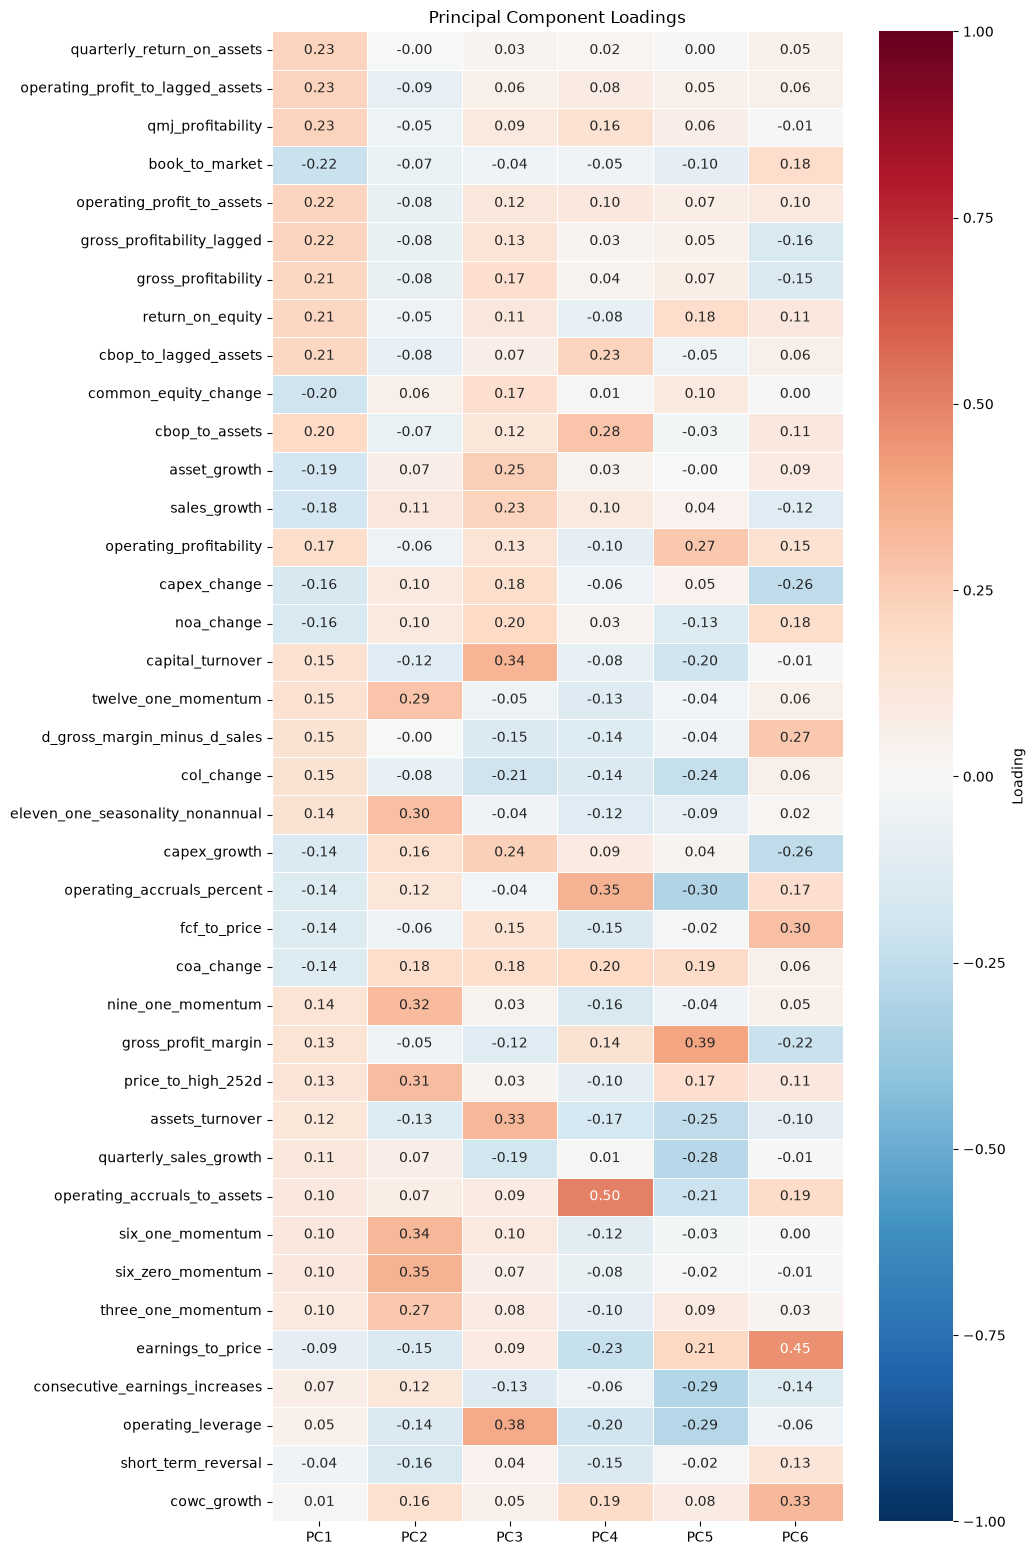

In [6]:
loadings = view_principal_components(monthly_returns, n_components=n_components)

fig, ax = plt.subplots(figsize=(max(6, 1.2 * n_components + 3), 0.35 * len(loadings) + 2))
sns.heatmap(
    loadings,
    ax=ax,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Loading'},
)
ax.set_title('Principal Component Loadings')
plt.tight_layout()
plt.show()

## How factors group within components

Assign each factor to the component on which it has its largest absolute loading, then list the factors that load meaningfully on each component, split by direction. A factor counts as loaded when its absolute loading is at least `RELATIVE_THRESHOLD` times the largest absolute loading in that component, so broad components such as PC1 are not missed.

In [7]:
RELATIVE_THRESHOLD = 0.5

theme = pd.Series({name: _factor_theme(FACTOR_MAPPINGS[name]['func']) for name in loadings.index})
primary = loadings.abs().idxmax(axis=1)
grouping = pd.DataFrame(
    {
        'theme': theme,
        'primary_pc': primary,
        'primary_loading': [loadings.loc[name, pc] for name, pc in primary.items()],
        'max_other_abs': [
            loadings.loc[name].drop(pc).abs().max() if n_components > 1 else np.nan
            for name, pc in primary.items()
        ],
    }
)
grouping['abs_loading'] = grouping['primary_loading'].abs()
grouping = (
    grouping
    .sort_values(['primary_pc', 'abs_loading'], ascending=[True, False])
    .drop(columns='abs_loading')
)
grouping.round(2)

,theme,primary_pc,primary_loading,max_other_abs
quarterly_return_on_assets,quality,PC1,0.23,0.05
operating_profit_to_lagged_assets,quality,PC1,0.23,0.09
qmj_profitability,quality,PC1,0.23,0.16
book_to_market,value,PC1,-0.22,0.18
operating_profit_to_assets,quality,PC1,0.22,0.12
gross_profitability_lagged,quality,PC1,0.22,0.16
gross_profitability,quality,PC1,0.21,0.17
return_on_equity,quality,PC1,0.21,0.18
common_equity_change,investment,PC1,-0.20,0.17
six_zero_momentum,momentum,PC2,0.35,0.10


In [8]:
for number, pc in enumerate(loadings.columns):
    column = loadings[pc]
    cutoff = RELATIVE_THRESHOLD * column.abs().max()
    positive = column[column >= cutoff].sort_values(ascending=False)
    negative = column[column <= -cutoff].sort_values()
    print(f'{pc} ({explained[number]:.1%} of variance)')
    print('  +  ' + (', '.join(f'{n} ({v:+.2f})' for n, v in positive.items()) or '-'))
    print('  -  ' + (', '.join(f'{n} ({v:+.2f})' for n, v in negative.items()) or '-'))

PC1 (42.2% of variance)
  +  quarterly_return_on_assets (+0.23), operating_profit_to_lagged_assets (+0.23), qmj_profitability (+0.23), operating_profit_to_assets (+0.22), gross_profitability_lagged (+0.22), gross_profitability (+0.21), return_on_equity (+0.21), cbop_to_lagged_assets (+0.21), cbop_to_assets (+0.20), operating_profitability (+0.17), capital_turnover (+0.15), twelve_one_momentum (+0.15), d_gross_margin_minus_d_sales (+0.15), col_change (+0.15), eleven_one_seasonality_nonannual (+0.14), nine_one_momentum (+0.14), gross_profit_margin (+0.13), price_to_high_252d (+0.13), assets_turnover (+0.12)
  -  book_to_market (-0.22), common_equity_change (-0.20), asset_growth (-0.19), sales_growth (-0.18), capex_change (-0.16), noa_change (-0.16), capex_growth (-0.14), operating_accruals_percent (-0.14), fcf_to_price (-0.14), coa_change (-0.14)
PC2 (13.8% of variance)
  +  six_zero_momentum (+0.35), six_one_momentum (+0.34), nine_one_momentum (+0.32), price_to_high_252d (+0.31), eleven

## Components by theme

Squared loadings within a component sum to one, so summing them by source theme gives the share of each component that comes from each theme. A component dominated by one theme means that theme's factors are largely redundant with each other; a component spread across themes captures something they share.

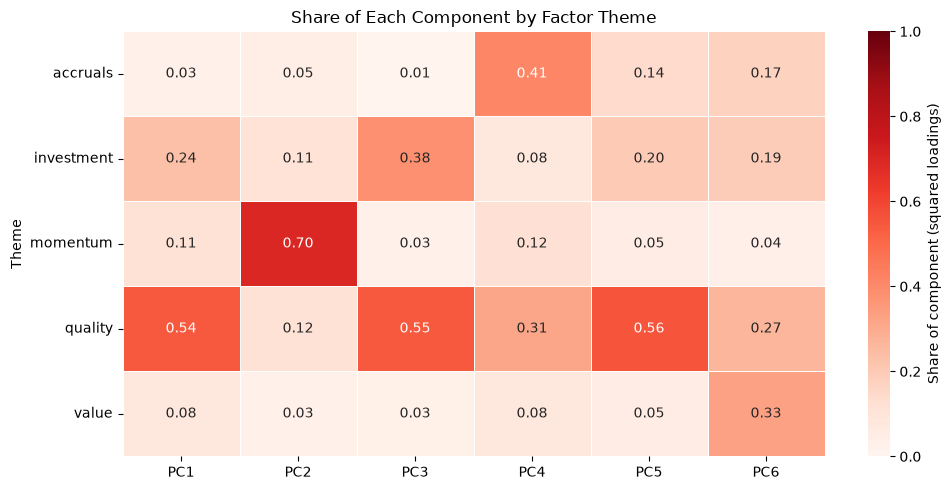

In [9]:
theme_share = (loadings ** 2).groupby(theme).sum()
fig, ax = plt.subplots(figsize=(max(6, 1.2 * n_components + 3), 0.6 * len(theme_share) + 2))
sns.heatmap(
    theme_share,
    ax=ax,
    annot=True,
    fmt='.2f',
    cmap='Reds',
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Share of component (squared loadings)'},
)
ax.set_title('Share of Each Component by Factor Theme')
ax.set_ylabel('Theme')
plt.tight_layout()
plt.show()

## PC scores over time

`pca.transform(scaled_returns)` gives each month's score on every retained component: how strongly that month's cross-section of factor returns points along each component. The fit below is the same one `view_principal_components` runs, so the components match the loadings above.

In [10]:
pca = PCA(n_components=n_components).fit(scaled)
pc_scores = pd.DataFrame(
    pca.transform(scaled),
    index=monthly_returns.index,
    columns=loadings.columns,
)
# Signs are arbitrary but the components themselves must match the loadings table
expected = loadings.reindex(monthly_returns.columns).abs().to_numpy()
assert np.allclose(np.abs(pca.components_.T), expected)
pc_scores.tail()

,PC1,PC2,PC3,PC4,PC5,PC6
date,,,,,,
2024-08-31,2.003202,1.050977,-1.365068,-0.359237,0.009837,0.513562
2024-09-30,-0.590108,0.003200,-0.509764,0.787595,-0.014826,0.492443
2024-10-31,-1.391797,1.645859,-3.492867,0.182132,1.045131,1.104124
2024-11-30,0.534355,1.501386,-1.745068,-2.048089,-1.003316,-0.576370
2024-12-31,3.961858,-0.292090,-1.586114,1.040006,-0.078879,-0.987414


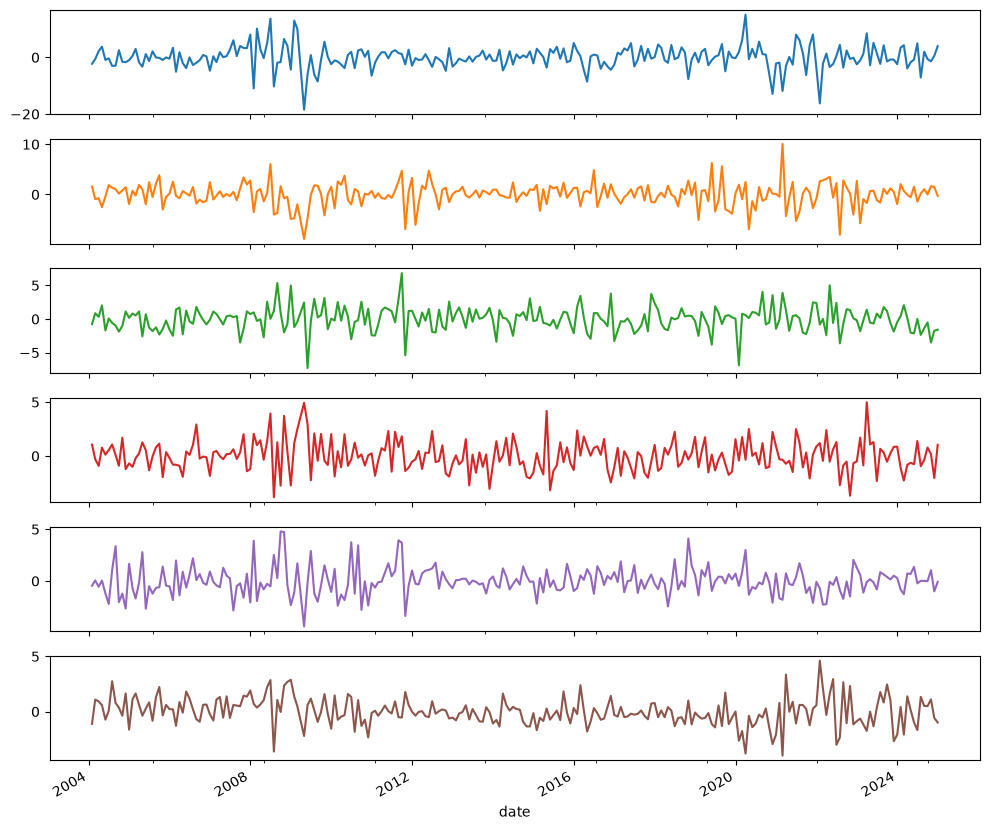

In [11]:
pc_scores.plot(subplots=True, figsize=(10, 1.4 * n_components), sharex=True, legend=False)
plt.tight_layout()
plt.show()

## Regress each factor on the PC scores

For every factor, regress its monthly return on the PC scores. The intercept is the alpha: return the components cannot explain. R-squared is the share of the factor's variance the components do explain, so a low R-squared marks a factor with a lot of its own variation, and a factor that looks original.

The scores are mean-zero and uncorrelated with each other, so the intercept always equals the factor's average monthly return. What the regression adds is its standard error: the alpha t-stat compares that average return to the factor's residual volatility.

In [12]:
X = np.column_stack([np.ones(len(pc_scores)), pc_scores.to_numpy()])
Y = monthly_returns.to_numpy()
coefficients = np.linalg.lstsq(X, Y, rcond=None)[0]
residuals = Y - X @ coefficients
dof = len(X) - X.shape[1]
residual_variance = (residuals ** 2).sum(axis=0) / dof
alpha_se = np.sqrt(residual_variance * np.linalg.inv(X.T @ X)[0, 0])
total_ss = ((Y - Y.mean(axis=0)) ** 2).sum(axis=0)

regressions = pd.DataFrame(
    {
        'theme': pd.Series({name: _factor_theme(FACTOR_MAPPINGS[name]['func']) for name in monthly_returns}),
        'alpha': coefficients[0],
        'alpha_annualized': coefficients[0] * 12,
        'alpha_t': coefficients[0] / alpha_se,
        'r_squared': 1 - (residuals ** 2).sum(axis=0) / total_ss,
    },
    index=monthly_returns.columns,
)
regressions.round(4)

,theme,alpha,alpha_annualized,alpha_t,r_squared
cowc_growth,accruals,0.0026,0.0317,3.9577,0.3989
operating_accruals_to_assets,accruals,0.0028,0.0341,8.6856,0.8954
operating_accruals_percent,accruals,0.0011,0.0134,3.0820,0.8687
asset_growth,investment,-0.0012,-0.0147,-2.4803,0.8119
capex_growth,investment,0.0015,0.0181,2.8133,0.7734
capex_change,investment,0.0006,0.0078,1.0762,0.7171
noa_change,investment,0.0020,0.0236,3.1766,0.6879
common_equity_change,investment,-0.0013,-0.0154,-2.2711,0.8135
coa_change,investment,0.0001,0.0006,0.0936,0.7546
col_change,investment,0.0006,0.0069,0.8894,0.6765


### Lowest R-squared

In [13]:
regressions.sort_values('r_squared').head(10).round(4)

,theme,alpha,alpha_annualized,alpha_t,r_squared
short_term_reversal,momentum,0.0044,0.0528,2.6209,0.2479
cowc_growth,accruals,0.0026,0.0317,3.9577,0.3989
consecutive_earnings_increases,quality,0.0011,0.0130,1.6962,0.4161
quarterly_sales_growth,investment,0.0007,0.0084,0.9287,0.4998
d_gross_margin_minus_d_sales,quality,0.0007,0.0087,0.9319,0.5801
fcf_to_price,value,0.0043,0.0516,6.0689,0.5968
three_one_momentum,momentum,-0.0027,-0.0325,-2.2111,0.6029
col_change,investment,0.0006,0.0069,0.8894,0.6765
noa_change,investment,0.0020,0.0236,3.1766,0.6879
capex_change,investment,0.0006,0.0078,1.0762,0.7171


### Highest alpha

In [14]:
regressions.sort_values('alpha', ascending=False).head(10).round(4)

,theme,alpha,alpha_annualized,alpha_t,r_squared
short_term_reversal,momentum,0.0044,0.0528,2.6209,0.2479
fcf_to_price,value,0.0043,0.0516,6.0689,0.5968
cbop_to_assets,quality,0.0035,0.0422,9.2032,0.8988
cbop_to_lagged_assets,quality,0.0033,0.0391,8.3775,0.9037
assets_turnover,quality,0.0032,0.0389,9.1598,0.8867
qmj_profitability,quality,0.0030,0.0360,8.2856,0.9467
operating_accruals_to_assets,accruals,0.0028,0.0341,8.6856,0.8954
cowc_growth,accruals,0.0026,0.0317,3.9577,0.3989
gross_profitability,quality,0.0026,0.0307,5.4854,0.9140
gross_profitability_lagged,quality,0.0024,0.0288,5.6491,0.9331
